In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sys
sys.path.append("..")
from src.io_utils import load_data
df = load_data("../data/health_study_dataset.csv")

**1. Scatterplotet (spridningsdiagram) hjälper oss att undersöka:**
- Verkar blodtrycket öka med åldern?
- Finns det något samband?
- Hur mycket varierar blodtrycket mellan personer i samma ålder?
- Finns det några avvikande värden?
- OBS: scatterplotet räknar inte ut någon modell. Det visar bara våra observationer.

**2. Linjär regression – beräkna ett samband**
- Nu har vi lagt till en röd linje i diagrammet. Det är en regressionslinje som representerar den linje som bäst sammanfattar det linjära sambandet mellan ålder och blodtryck enligt minsta kvadratmetoden.
- Med den kan vi exempelvis uppskatta: vilket systoliskt blodtryck modellen förväntar sig vid en viss ålder.
- Vår linjära regression kan uppskatta blodtrycket även vid åldrar där vi saknar observationer, eftersom modellen utgår från den övergripande trenden i hela datasetet

**3. Men var kommer signifikans in?**
Här är en viktig skillnad:
- Linjär regression: Vi undersöker och modellerar sambandet mellan två variabler.
- Signifikansanalys: Vi kan undersöka om det finns statistiskt stöd för att sambandet skiljer sig från noll i populationen.
- Vi vill undersöka om lutningen i regressionslinjen är tillräckligt tydlig för att det ska vara osannolikt att den uppstått enbart på grund av slumpmässig variation

### Utökad analys och visualisering
- Lägg till minst en ny analys eller graf som ger en djupare förståelse (t.ex. relationen mellan blodtryck och ålder, eller sjukdomsförekomst per kön).

#### - Nollhypotes (H₀): Det finns inget linjärt samband mellan ålder och blodtryck (lutningen är 0)
#### - Alternativ hypotes (H₁): Det finns ett linjärt samband (lutningen skiljer sig från 0)

In [10]:
# MULTIPEL REGRESSIONSANALYS

import statsmodels.api as sm
np.random.seed(42)

# # # Source - https://stackoverflow.com/a/40902719
# # # Posted by piRSquared
# # # Retrieved 2026-11-20, License - CC BY-SA 3.0

# (Y) beroende variabel: systolic_bp
# (X) oberoende variabler: age, weight, cholesterol, smoking, disease, sex

# KOMMENTAR
# samtliga oberoende variabler är numeriska utom sex (M/F) och smoking (Yes/No)
# dessa två behöver konverteras från strings till numeriska variabler (1/0)

c_smoker = df["smoker"].map({"Yes": 1, "No": 0}) # omvandlar (convert) smoker från Yes/No till 1/0
c_sex = df["sex"].map({"M": 1, "F": 0})
df_drop = df.drop(columns=["id", "smoker","sex"])            # tar bort originalkolumnen
df_assign = df_drop.assign(smoker=c_smoker, sex=c_sex)      # lägger till den omkodade kolumnen
df_processed = df_assign

# plockar ut variablerna til X och Y
# oberoende variabler
X = df_processed[["age", "height", "weight", "cholesterol", "disease", "smoker", "sex"]]

# test..
X = df_processed[["age"]]
# beroende variabel
Y = df_processed[["systolic_bp"]]

# model = sm.OLS(Y, X)
# results = model.fit()
# print(results.summary())



In [11]:
# MULTIPEL REGRESSIONSANALYS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
np.random.seed(42)

# Källa: https://www.youtube.com/watch?v=KYNuzfn5Fx0
# Source - https://stackoverflow.com/a/40902719
# Posted by piRSquared
# Retrieved 2026-11-20, License - CC BY-SA 3.0

# (Y) beroende variabel: systolic_bp
# (X) oberoende variabler: age, weight, cholesterol, smoking, disease, sex

# KOMMENTAR
# samtliga oberoende variabler är numeriska utom sex (M/F) och smoking (Yes/No)
# dessa två behöver konverteras från strings till numeriska variabler (1/0)

c_smoker = df["smoker"].map({"Yes": 1, "No": 0}) # omvandlar (convert) smoker från Yes/No till 1/0
c_sex = df["sex"].map({"M": 1, "F": 0})
df_drop = df.drop(columns=["id", "smoker","sex"])            # tar bort originalkolumnen
df_assign = df_drop.assign(smoker=c_smoker, sex=c_sex)      # lägger till den omkodade kolumnen
df_processed = df_assign

# plockar ut variablerna til X och Y
# oberoende variabler
X = df_processed[["age", "height", "weight", "cholesterol", "disease", "smoker", "sex"]]

# beroende variabel
Y = df_processed["systolic_bp"]

# lägger till en konstantkolumn (med värdet 1) i X
# konstanten gör att modellen kan beräkna ett grundvärde (intercept)
# som blir modellens konstant = fasta stardvärde: Blodtryck = 99.9181
# + (0.5235 * ålder)
# + (0.0533 * längd)
# + (0.1603 * vikt)
X_const = sm.add_constant(X)

# sm.OLS() = Ordinary Least Squares (minsta kvadratmetoden)
# Skapar en linjär regressionsmodell som beräknar vilka koefficienter som bäst passar datan
# .fit() = genomför beräkningen och anpassar modellen till datan genom att hitta de bästa koefficienterna
model = sm.OLS(Y, X_const).fit()

# beräknar modellens koefficienter och andra statistiska resultat
# visar bland annat koefficienter, p-värden och förklaringsgrad
print(model.summary())

# TOLKNING

## R-squared = 0.407
# Våra sju oberoende variabler (ålder, vikt, längd osv.) kan tillsammans
# förklara 40,7 % av skillnaderna i systoliskt blodtryck mellan de 800 personerna.
# Modellen hittar vissa mönster. Exempelvis tenderar äldre personer att ha
# högre blodtryck och personer med högre vikt tenderar också att ha högre blodtryck.
# Men dessa mönster förklarar inte alla skillnader mellan personerna.
# De återstående 59,3 % är variation som modellen inte kan förklara
# med de variabler vi har valt.

## Adjusted R-squared:  hjälper oss bedöma om modellens förklaringsgrad är bra 
# i förhållande till antalet variabler.

## Covariance Type = nonrobust
# Det här handlar om hur modellen beräknar osäkerheten i sina resultat.
# Nonrobust betyder att modellen använder vanliga standardfel.

## Method = Least Squares
# Det betyder att modellen använder metoden Ordinary Least Squares (OLS).
# Den försöker hitta den regressionslinje som minimerar summan av de kvadrerade 
# skillnaderna mellan.

## Prob (F-statistic) = 1.16e-85
# Detta är p-värdet för hela regressionsmodellen.
# 1.16e-85 betyder 1.16 × 10⁻⁸⁵, alltså ett extremt litet tal nära noll.
# Eftersom p-värdet är mycket mindre än 0.05 är modellen statistiskt signifikant.
# Det innebär att minst en av de oberoende variablerna har ett
# statistiskt signifikant samband med systoliskt blodtryck.

## F-statistic = 77.73
# Detta är ett testvärde som jämför två modeller:
# En modell som använder medelvärdet av systoliskt blodtryck
# för att förutsäga blodtrycket hos alla personer,
# och vår regressionsmodell som använder ålder.
# Ett högt F-värde tyder på att modellen med ålder
# förklarar mer av variationen i blodtrycket.

## Log-Likelihood = -2964.6
# Visar hur väl regressionsmodellen passar till de faktiska
# observationerna i datasetet.
# Värdet används främst för att jämföra olika modeller.
# Ett högre värde (närmare noll) innebär generellt en bättre
# modellpassning.

#===============================================================

# Ålder (age)
# Koefficient: 0.5235
# P-värde: 0.000
#
# Koefficienten 0.5235 innebär att när åldern ökar med ett år
# förväntas det systoliska blodtrycket öka med cirka 0.52 mmHg,
# om övriga variabler hålls konstanta.
#
# P-värdet är mindre än 0.05, vilket innebär att sambandet
# är statistiskt signifikant.
#
# Tolkning:
# Ålder har ett positivt och statistiskt signifikant samband
# med systoliskt blodtryck.



                            OLS Regression Results                            
Dep. Variable:            systolic_bp   R-squared:                       0.407
Model:                            OLS   Adj. R-squared:                  0.402
Method:                 Least Squares   F-statistic:                     77.73
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.16e-85
Time:                        11:24:08   Log-Likelihood:                -2964.6
No. Observations:                 800   AIC:                             5945.
Df Residuals:                     792   BIC:                             5983.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          99.9181      8.784     11.375      

                            OLS Regression Results                            
Dep. Variable:            systolic_bp   R-squared:                       0.407
Model:                            OLS   Adj. R-squared:                  0.402
Method:                 Least Squares   F-statistic:                     77.73
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.16e-85
Time:                        11:24:08   Log-Likelihood:                -2964.6
No. Observations:                 800   AIC:                             5945.
Df Residuals:                     792   BIC:                             5983.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          99.9181      8.784     11.375      

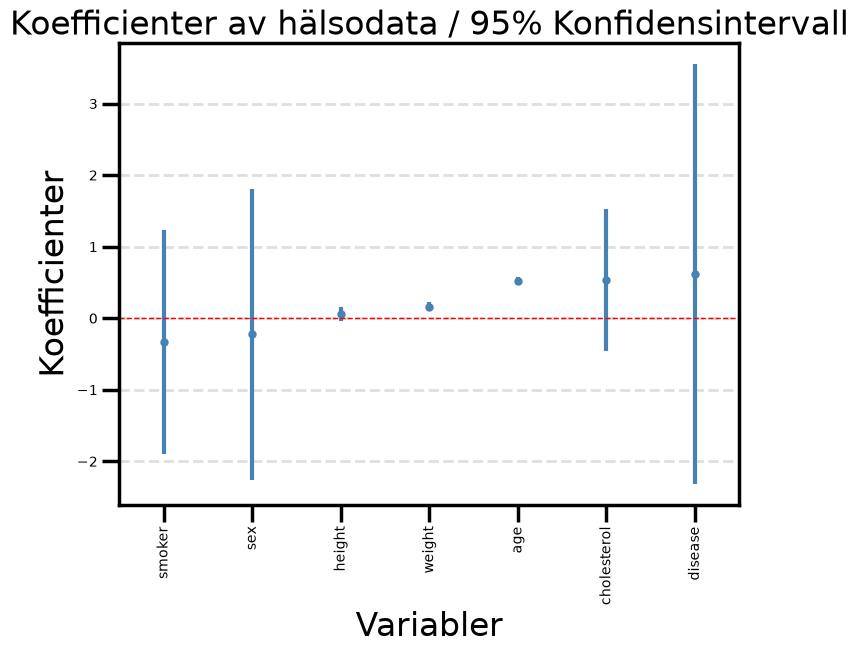

None


In [ ]:
# Koefficientgraf (Coefficient plot)

# källa: https://medium.com/analytics-vidhya/create-your-own-coefficient-plot-function-in-python-aadb9fe27a77

import pandas as pd
import numpy as np
import seaborn as sns # ?
import matplotlib.pyplot as plt
%matplotlib inline

# BYGG MODELLEN
# importera paket
import statsmodels.api as sm # ?


def coefplot(df):
    """
    Denna metod utför en multipel regressionsanalys och presenterar sedan 
    tabellen och  koefficientgraf.
    
    """
    c_smoker = df["smoker"].map({"Yes": 1, "No": 0}) # omvandlar (convert) smoker från Yes/No till 1/0
    c_sex = df["sex"].map({"M": 1, "F": 0})
    df_drop = df.drop(columns=["id", "smoker","sex"])      # tar bort originalkolumnen
    df_assign = df_drop.assign(smoker=c_smoker, sex=c_sex) # lägger till den omkodade kolumnen
    df_processed = df_assign

    # plockar ut variablerna til X och Y
    X = df_processed[["age", "height", "weight", "cholesterol", "disease", "smoker", "sex"]] # oberoende variabler
    Y = df_processed["systolic_bp"] # beroende variabel

    # lägger till en konstantkolumn (med värdet 1) i X
    # konstanten gör att modellen kan beräkna ett grundvärde (intercept)
    # som blir modellens konstant = fasta stardvärde: Blodtryck = 99.9181
    X = sm.add_constant(X)

    # sm.OLS() = Ordinary Least Squares (minsta kvadratmetoden)
    # Skapar en linjär regressionsmodell som beräknar vilka koefficienter som bäst passar datan
    # .fit() = genomför beräkningen och anpassar modellen till datan genom att hitta de bästa koefficienterna
    model = sm.OLS(Y, X).fit()

    # meräknar och skriver ut modellens MSE (Mean Squared Error)
    # MSE visar det genomsnittliga kvadrerade felet mellan modellens
    # förutsagda blodtrycksvärden och de faktiska blodtrycksvärdena
    model.mse_resid

    # tabellens resultat
    model.summary()

    # förbered figuren

    coef_df = pd.DataFrame(model.summary().tables[1].data) # hämtar koefficienttabellen från regressionen och gör om den till en Pandas-tabell
    coef_df.columns = coef_df.iloc[0]                 # tar första raden och gör den till kolumnnamn, till exempel coef, std err och P>|t|
    coef_df=coef_df.drop(0)                           # tar bort första raden eftersom den nu redan används som kolumnnamn
    coef_df = coef_df.set_index(coef_df.columns[0])   # gör första kolumnen till radnamn, så att variablerna (age, weight osv.) blir index
    coef_df = coef_df.astype(float)                   # gör om tabellens värden till decimaltal så att Python kan räkna med dem
    errors_lower = coef_df["coef"] - coef_df["[0.025"] # räknar ut hur långt det är från koefficienten till den nedre konfidensgränsen
    errors_upper = coef_df["0.975]"] - coef_df["coef"]  # räknar ut hur långt det är från koefficienten till den övre konfidensgränsen
    coef_df["errors_lower"] = errors_lower               # skapar en ny kolumn som lägger till de uträknade avstånden i DataFrame
    coef_df["errors_upper"] = errors_upper               # skapar en ny kolumn som lägger till de uträknade avstånden i DataFrame
    coef_df = coef_df.drop(["const"])                    # tar bort konstanten (interceptet) från tabellen eftersom vi bara vill visa våra
                                                         # förklarande variabler i koefficientdiagrammet, inte modellens startvärde.
    coef_df = coef_df.sort_values(by=["coef"])        # sorterar variablerna efter deras koefficientvärde, från lägsta till högsta, så att 
                                                      # de visas i den ordningen i koefficientdiagrammet
    # skriv ut koefficienterna 
    variables = list(coef_df.index.values)            # hämtar alla variabelnamn från tabellen och sparar dem i en lista
    coef_df['variables'] = variables                  # lägger till en kolumn med variables (etiketter smoker, sex, osv..)
    sns.set_context("poster")                         # Gör text och diagrammets detaljer större - ta ev. bort..

    fig, ax = plt.subplots(figsize=(8, 6))           # ta fram figuren

    # error-stapel för 95% konfidensintervall (tas fram med pandas(plot))
    coef_df.plot(
        x="variables",       # Visar variabelnamnen på X-axeln
        y="coef",             # Visar koefficientvärdena på Y-axeln
        kind="bar",           # Väljer stapeldiagram
        ax=ax,                # Placerar diagrammet på en befintlig Matplotlib-axel
        color="none",         # Gör staplarna genomskinliga
        fontsize=10,          # Bestämmer textstorleken
        ecolor="steelblue",   # Gör felstaplarna blå
        capsize=0,            # Tar bort små tvärstreck i felstaplarnas ändar
        yerr=[coef_df["errors_lower"], coef_df["errors_upper"]], # Anger felmarginalerna som ska visas
        legend=False          # döljer legend
        )

    # titlar och etiketter
    plt.title("Koefficienter av hälsodata / 95% Konfidensintervall")
    ax.set_ylabel("Koefficienter")
    ax.set_xlabel("Variabler")

    # koefficienter
    ax.scatter(
        x=np.arange(coef_df.shape[0]),  # skapar en position på X-axeln för varje variabel i tabellen
        marker="o",                     # visar varje koefficient som en rund punkt
        s=16,                           # bestämmer punktens storlek
        y=coef_df["coef"],              # placerar punkterna utifrån variablernas koefficientvärden på Y-axeln
        color="steelblue"               # Gör punkterna blå
    )

    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    # ritar en referenslinje vid värdet 0 på Y-axeln
    print(model.summary())
    ax.axhline(y=0, linestyle='--', color='red', linewidth=1)
    plt.show()

result = coefplot(df)
print(result)


### **Tolkning och källor:** 

Diagrammet visar regressionskoefficienterna (blå punkter) för de sju oberoende variablerna tillsammans med deras 95-procentiga konfidensintervall (blå vertikala streck). Här illustreras samma resultat som presenteras i tabellen ovan, med skillnaden att koefficienterna har sorterats i stigande ordning, från det lägsta till det högsta värdet (vänster till höger). Den röda streckade linjen markerar noll, vilket innebär att konfidensintrevall som korsar linjen inte är statistiskt signifikanta på 5-procentsnivån (P > 0.05). Diagrammet visar, liksom tabellen, att ålder och vikt har positiva statistiska samband med systoliskt blodtryck, medan övriga variablar inte uppvisar statistiskt signifikanta samband. 

